# PCA Based Gene Selection


## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## Step 2: Load the GSE6613 Dataset

In [2]:
!pip install GEOparse -q

In [3]:
import GEOparse

gse = GEOparse.get_GEO(geo="GSE6613", destdir="./")
print("Dataset loaded successfully!")

04-May-2026 04:03:20 DEBUG utils - Directory ./ already exists. Skipping.
DEBUG:GEOparse:Directory ./ already exists. Skipping.
04-May-2026 04:03:20 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE6nnn/GSE6613/soft/GSE6613_family.soft.gz to ./GSE6613_family.soft.gz
INFO:GEOparse:Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE6nnn/GSE6613/soft/GSE6613_family.soft.gz to ./GSE6613_family.soft.gz
100%|██████████| 16.1M/16.1M [00:00<00:00, 142MB/s]
04-May-2026 04:03:20 DEBUG downloader - Size validation passed
DEBUG:GEOparse:Size validation passed
04-May-2026 04:03:20 DEBUG downloader - Moving /tmp/tmpz7faqb63 to /content/GSE6613_family.soft.gz
DEBUG:GEOparse:Moving /tmp/tmpz7faqb63 to /content/GSE6613_family.soft.gz
04-May-2026 04:03:20 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE6nnn/GSE6613/soft/GSE6613_family.soft.gz
DEBUG:GEOparse:Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE6nnn/GSE6613/soft/GSE6613

Dataset loaded successfully!


In [4]:
samples = gse.pivot_samples('VALUE')
print("Shape of samples matrix (genes x samples):", samples.shape)
samples.head()

Shape of samples matrix (genes x samples): (22283, 105)


name,GSM153404,GSM153405,GSM153406,GSM153407,GSM153408,GSM153409,GSM153410,GSM153411,GSM153412,GSM153413,...,GSM153499,GSM153500,GSM153501,GSM153502,GSM153503,GSM153504,GSM153505,GSM153506,GSM153507,GSM153508
ID_REF,,,,,,,,,,,,,,,,,,,,,
1007_s_at,114.5,105.1,145.7,168.7,94.3,96.2,155.8,99.8,100.9,106.4,...,153.8,103.7,132.8,195.5,82.6,28.2,163.9,29.0,104.8,32.8
1053_at,64.4,58.4,52.5,45.4,51.3,50.7,42.2,6.7,44.0,55.5,...,44.0,70.5,61.9,52.2,61.2,67.6,101.9,46.8,74.9,78.1
117_at,206.3,179.8,192.0,263.6,211.9,149.5,157.3,216.6,230.5,224.1,...,268.9,48.6,193.6,132.5,165.5,146.0,291.4,246.2,251.2,210.0
121_at,507.0,497.8,346.3,430.7,485.5,437.6,424.1,678.7,434.1,592.8,...,403.6,559.1,569.7,532.8,525.7,603.9,479.7,271.9,506.1,270.4
1255_g_at,34.5,18.0,40.1,40.5,22.8,6.4,27.4,5.2,34.7,18.6,...,44.8,39.5,30.5,65.8,54.3,19.3,61.0,40.8,29.5,82.2


In [5]:
gpl = gse.gpls[list(gse.gpls.keys())[0]]
probe_to_gene = dict(zip(gpl.table["ID"].astype(str), gpl.table["Gene Symbol"]))

samples.index = samples.index.astype(str).map(lambda x: probe_to_gene.get(x, x))

samples = samples[samples.index.notna()]
samples = samples[samples.index != '']
samples = samples[samples.index.str.strip() != '']

print("Shape after mapping to gene symbols:", samples.shape)
samples.head()

Shape after mapping to gene symbols: (21225, 105)


name,GSM153404,GSM153405,GSM153406,GSM153407,GSM153408,GSM153409,GSM153410,GSM153411,GSM153412,GSM153413,...,GSM153499,GSM153500,GSM153501,GSM153502,GSM153503,GSM153504,GSM153505,GSM153506,GSM153507,GSM153508
ID_REF,,,,,,,,,,,,,,,,,,,,,
DDR1 /// MIR4640,114.5,105.1,145.7,168.7,94.3,96.2,155.8,99.8,100.9,106.4,...,153.8,103.7,132.8,195.5,82.6,28.2,163.9,29.0,104.8,32.8
RFC2,64.4,58.4,52.5,45.4,51.3,50.7,42.2,6.7,44.0,55.5,...,44.0,70.5,61.9,52.2,61.2,67.6,101.9,46.8,74.9,78.1
HSPA6,206.3,179.8,192.0,263.6,211.9,149.5,157.3,216.6,230.5,224.1,...,268.9,48.6,193.6,132.5,165.5,146.0,291.4,246.2,251.2,210.0
PAX8,507.0,497.8,346.3,430.7,485.5,437.6,424.1,678.7,434.1,592.8,...,403.6,559.1,569.7,532.8,525.7,603.9,479.7,271.9,506.1,270.4
GUCA1A,34.5,18.0,40.1,40.5,22.8,6.4,27.4,5.2,34.7,18.6,...,44.8,39.5,30.5,65.8,54.3,19.3,61.0,40.8,29.5,82.2


## Step 3: Prepare Feature Matrix

In [6]:
X = samples.T
gene_names = X.columns.tolist()
print("Feature matrix shape (samples x genes):", X.shape)

Feature matrix shape (samples x genes): (105, 21225)


In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Standardization complete. Shape:", X_scaled.shape)

Standardization complete. Shape: (105, 21225)


## Step 4: Apply PCA (variance = 0.95)


In [8]:
pca_95 = PCA(n_components=0.95, random_state=2020)
X_pca_95 = pca_95.fit_transform(X_scaled)
n_components_95 = pca_95.n_components_
print(f"Number of components selected (95% variance): {n_components_95}")
print(f"Total variance explained: {sum(pca_95.explained_variance_ratio_)*100:.2f}%")

Number of components selected (95% variance): 91
Total variance explained: 95.14%


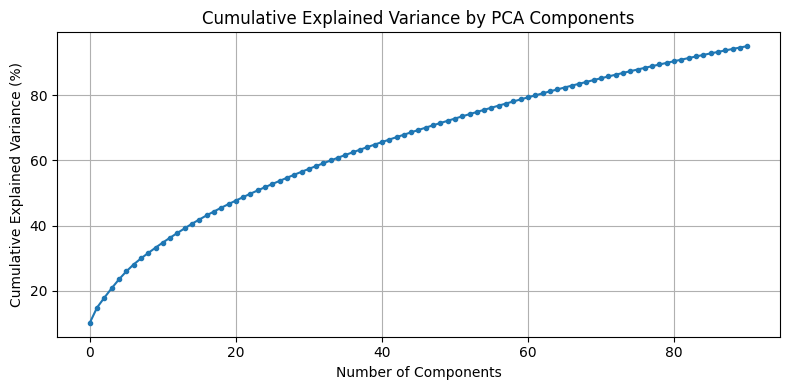

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(pca_95.explained_variance_ratio_ * 100), marker='o', markersize=3)
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.title('Cumulative Explained Variance by PCA Components')
plt.grid(True)
plt.tight_layout()
plt.show()

## Step 5: Gene Selection Using Top 5 PCs

In [10]:
def get_top_genes(pca_model, gene_names, n_top_pcs=5, n_top_genes=20):

    loadings = pca_model.components_[:n_top_pcs]

    variances = pca_model.explained_variance_ratio_[:n_top_pcs]

    weighted_loadings = np.abs(loadings) * variances[:, np.newaxis]

    gene_weights = weighted_loadings.sum(axis=0)

    gene_scores = pd.DataFrame({'Gene': gene_names, 'Weight': gene_weights})
    gene_scores = gene_scores.sort_values('Weight', ascending=False).reset_index(drop=True)

    return gene_scores.head(n_top_genes)

In [11]:

top_genes_5pc = get_top_genes(pca_95, gene_names, n_top_pcs=5, n_top_genes=20)

print("=== Top 20 Genes Using Top 5 PCs ===")
print(top_genes_5pc.to_string(index=False))

=== Top 20 Genes Using Top 5 PCs ===
                                                            Gene   Weight
EIF4A2 /// MIR1248 /// SNORA4 /// SNORA63 /// SNORA81 /// SNORD2 0.002841
                                                            PURA 0.002805
                                                          PTGES3 0.002764
                                                          ANP32A 0.002719
                                                           RPL19 0.002700
                                                            NPM1 0.002694
                                     H3F3A /// H3F3AP4 /// H3F3B 0.002690
                                                   HBA1 /// HBA2 0.002682
                                                             HBB 0.002679
                                                           PARK7 0.002677
                                                             HBB 0.002675
                                                             MSN 0.002674
 

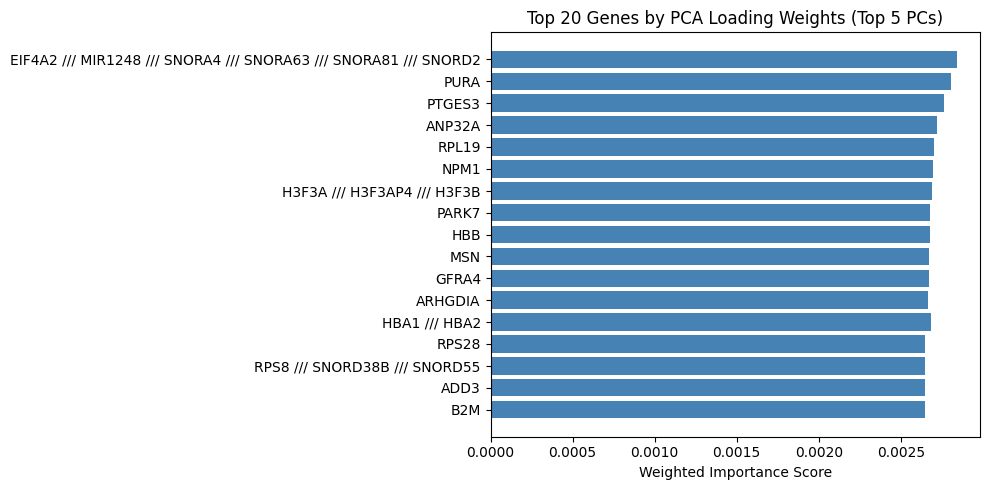

In [12]:
plt.figure(figsize=(10, 5))
plt.barh(top_genes_5pc['Gene'][::-1], top_genes_5pc['Weight'][::-1], color='steelblue')
plt.xlabel('Weighted Importance Score')
plt.title('Top 20 Genes by PCA Loading Weights (Top 5 PCs)')
plt.tight_layout()
plt.show()

## Step 6: Rerun Using Top 10 PCs

In [13]:
top_genes_10pc = get_top_genes(pca_95, gene_names, n_top_pcs=10, n_top_genes=20)

print("=== Top 20 Genes Using Top 10 PCs ===")
print(top_genes_10pc.to_string(index=False))

=== Top 20 Genes Using Top 10 PCs ===
                       Gene   Weight
                      EPHB2 0.003390
                      GFRA4 0.003384
                       RGS6 0.003322
                      CTAG2 0.003319
                     DNASE1 0.003317
                    CXorf36 0.003311
H3F3A /// H3F3B /// MIR4738 0.003288
                      EFCC1 0.003276
H3F3A /// H3F3AP4 /// H3F3B 0.003273
          CNN3P1 /// CNN3P1 0.003271
                       MAU2 0.003253
                     TUBB7P 0.003253
                      SYT17 0.003246
                      PARK7 0.003244
                      HUWE1 0.003239
                    RHOBTB2 0.003238
                    SEC14L3 0.003219
                       ADD3 0.003216
                      KCNJ1 0.003201
H3F3A /// H3F3B /// MIR4738 0.003200


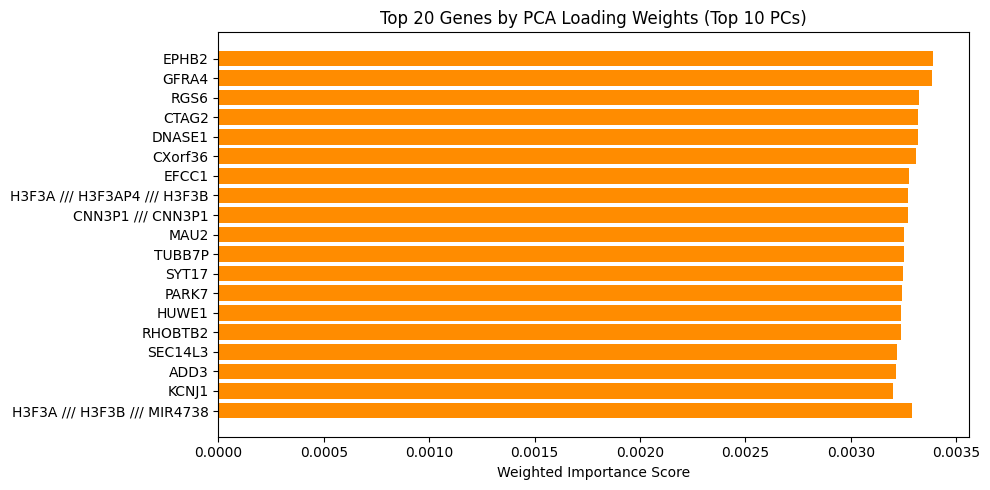

In [14]:
plt.figure(figsize=(10, 5))
plt.barh(top_genes_10pc['Gene'][::-1], top_genes_10pc['Weight'][::-1], color='darkorange')
plt.xlabel('Weighted Importance Score')
plt.title('Top 20 Genes by PCA Loading Weights (Top 10 PCs)')
plt.tight_layout()
plt.show()

## Step 7: Compare the Two Lists

In [15]:
comparison = pd.DataFrame({
    'Rank': range(1, 21),
    'Top 5 PCs': top_genes_5pc['Gene'].values,
    'Top 10 PCs': top_genes_10pc['Gene'].values
})
comparison['Same?'] = comparison['Top 5 PCs'] == comparison['Top 10 PCs']
print(comparison.to_string(index=False))

common = set(top_genes_5pc['Gene']) & set(top_genes_10pc['Gene'])
print(f"\nNumber of genes common to both lists: {len(common)}")
print("Common genes:", sorted(common))

 Rank                                                        Top 5 PCs                  Top 10 PCs  Same?
    1 EIF4A2 /// MIR1248 /// SNORA4 /// SNORA63 /// SNORA81 /// SNORD2                       EPHB2  False
    2                                                             PURA                       GFRA4  False
    3                                                           PTGES3                        RGS6  False
    4                                                           ANP32A                       CTAG2  False
    5                                                            RPL19                      DNASE1  False
    6                                                             NPM1                     CXorf36  False
    7                                      H3F3A /// H3F3AP4 /// H3F3B H3F3A /// H3F3B /// MIR4738  False
    8                                                    HBA1 /// HBA2                       EFCC1  False
    9                                         

#Step 8: Discussion
###1) Differences between the two lists:
There is difference in  the produced gene list by top 5 and 10 PCs. From the data, each PC captures different patterns of variation. Here, the first shows the largest part of variance. This observation gets subtler as we progress. When used top 5 PCs, the list of genes strongly follows the variations of these 5 PCs. But when we add top 10 PCs, we add more variance to the gene list. This is why the top 10 PCs differs from top 5 PCs.

###2) Suitability of PCA:
Because PCA is unsupervised, it doesn't have the requirement of labeled data. Which is really useful for noisy data or unlabeled data. It also reduces dimensionality which allows to work with genes with much higher dimensions.